# SLE multi-dataset batch correction pipeline (mean-only ComBat)
Steps: load -> harmonize scale -> filter genes -> ComBat -> evaluate -> disease tests -> save.
Input: database_robust.csv (original, BEFORE any z-scoring).

## 0. Setup (Colab: run once, then Runtime > Restart session)

In [ ]:
!pip install inmoose statsmodels -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 59.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 96.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.9/193.9 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account 

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from inmoose.pycombat import pycombat_norm
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

INPUT = "database_robust.csv"
if IN_COLAB and not os.path.exists(INPUT):
    files.upload()          # choose database_robust.csv

Saving database_robust.csv to database_robust.csv


## 1. Load data and define batches (study x platform)

In [ ]:
df = pd.read_csv(INPUT)
genes = ["MTHFR", "TYMS", "MTR", "MTRR", "CYP1A1", "GSTM1", "GSTT1",
         "GSTP1", "TLR2", "TLR4", "TLR7", "TLR9", "STAT4"]
df["batch"] = df["GSE_ID"] + "_" + df["GPL"]
assert df["GSM_ID"].is_unique, "Duplicate sample IDs"

print(df["batch"].value_counts())
print(pd.crosstab(df["batch"], df["Disease_State"]))

batch
GSE45291_GPL13158    805
GSE39088_GPL570      142
GSE32591_GPL14663     93
GSE10325_GPL96        67
GSE38351_GPL570       40
GSE38351_GPL96        34
GSE72747_GPL570       30
Name: count, dtype: int64
Disease_State      Healthy Control  Other/Unknown  SLE
batch                                                 
GSE10325_GPL96                  28              0   39
GSE32591_GPL14663               29             64    0
GSE38351_GPL570                 36              4    0
GSE38351_GPL96                  12              8   14
GSE39088_GPL570                 64              0   78
GSE45291_GPL13158               20            493  292
GSE72747_GPL570                 10              0   20


## 2. Harmonize scale
GSE10325 and GSE38351 are raw intensities -> log2.
-1.00 values are flag codes (no variance) -> NaN before log2.
GSE39088 / GSE72747 are already centred; GSE32591 / GSE45291 already log-scale.

In [ ]:
RAW_SETS = ["GSE10325", "GSE38351"]
mask = df["GSE_ID"].isin(RAW_SETS)

vals = df.loc[mask, genes]
vals = vals.where(vals > 0)                 # -1 and any <=0 -> NaN
df.loc[mask, genes] = np.log2(vals)

print(df.groupby("batch")[genes[:4]].median().round(2))

                   MTHFR  TYMS   MTR  MTRR
batch                                     
GSE10325_GPL96      4.33  6.91  8.82  8.34
GSE32591_GPL14663   4.84  7.58  7.05  8.06
GSE38351_GPL570     6.86  3.13  7.65  8.16
GSE38351_GPL96      3.79  4.75  6.69  6.85
GSE39088_GPL570     0.02  0.00 -0.02 -0.00
GSE45291_GPL13158   3.64  4.01  6.46  5.65
GSE72747_GPL570    -0.00 -0.03  0.02  0.02


## 3. Drop genes ComBat cannot model
(zero variance or missing within any batch)

In [ ]:
bad = []
for g in genes:
    sd_per_batch = df.groupby("batch")[g].std()
    if sd_per_batch.isna().any() or (sd_per_batch == 0).any() or df[g].isna().any():
        bad.append(g)
genes_ok = [g for g in genes if g not in bad]
print("Excluded genes:", bad)
print("Genes kept:", genes_ok)

Excluded genes: ['GSTM1', 'TLR9']
Genes kept: ['MTHFR', 'TYMS', 'MTR', 'MTRR', 'CYP1A1', 'GSTT1', 'GSTP1', 'TLR2', 'TLR4', 'TLR7', 'STAT4']


## 4. ComBat (mean-only = primary; full = sensitivity)

In [ ]:
expr = df[genes_ok].T                       # genes x samples
expr.columns = df["GSM_ID"].values

disease_clean = df["Disease_State"].replace(
    {"Healthy Control": "Healthy", "Other/Unknown": "Other", "SLE": "SLE"})
covar = pd.get_dummies(disease_clean, drop_first=True).astype(float)
covar.index = df["GSM_ID"].values           # columns: Other, SLE

batch = df["batch"].values
disease = df["Disease_State"].values

corrected_mo   = pycombat_norm(expr, batch, covar_mod=covar, mean_only=True)  # PRIMARY
corrected_full = pycombat_norm(expr, batch, covar_mod=covar)                  # sensitivity
print(corrected_mo.shape, corrected_full.shape)

(11, 1211) (11, 1211)


## 5. Quantify batch correction

In [ ]:
def r2_by_group(values, groups):
    """One-way ANOVA R^2: fraction of variance explained by a grouping."""
    values = np.asarray(values, float)
    ss_tot = ((values - values.mean()) ** 2).sum()
    ss_between = sum(len(v) * (v.mean() - values.mean()) ** 2
                     for _, v in pd.Series(values).groupby(np.asarray(groups)))
    return ss_between / ss_tot

def evaluate(data, label):
    X = data.T.values
    Xz = (X - X.mean(0)) / X.std(0)
    pcs = PCA(2).fit_transform(Xz)
    return {
        "stage": label,
        "mean batch R2 (genes)":   np.mean([r2_by_group(X[:, i], batch)   for i in range(X.shape[1])]),
        "mean disease R2 (genes)": np.mean([r2_by_group(X[:, i], disease) for i in range(X.shape[1])]),
        "PC1 batch R2":            r2_by_group(pcs[:, 0], batch),
        "PC2 batch R2":            r2_by_group(pcs[:, 1], batch),
        "silhouette (batch)":      silhouette_score(Xz, batch),
        "silhouette (disease)":    silhouette_score(Xz, disease),
    }

metrics = pd.DataFrame([evaluate(expr, "Before"),
                        evaluate(corrected_full, "ComBat (full)"),
                        evaluate(corrected_mo, "ComBat (mean-only)")]).set_index("stage").T
print(metrics.round(3))
metrics.round(4).to_csv("metrics_batch_correction.csv")

# per-gene table
per_gene = pd.DataFrame({
    "batch R2 before":     [r2_by_group(expr.loc[g], batch)           for g in genes_ok],
    "batch R2 after":      [r2_by_group(corrected_mo.loc[g], batch)   for g in genes_ok],
    "disease R2 before":   [r2_by_group(expr.loc[g], disease)         for g in genes_ok],
    "disease R2 after":    [r2_by_group(corrected_mo.loc[g], disease) for g in genes_ok],
}, index=genes_ok).round(3)
print(per_gene)
per_gene.to_csv("metrics_per_gene.csv")

stage                    Before  ComBat (full)  ComBat (mean-only)
mean batch R2 (genes)     0.919          0.057               0.137
mean disease R2 (genes)   0.177          0.285               0.265
PC1 batch R2              0.970          0.138               0.204
PC2 batch R2              0.938          0.016               0.062
silhouette (batch)        0.404         -0.110               0.063
silhouette (disease)      0.139          0.105               0.232
        batch R2 before  batch R2 after  disease R2 before  disease R2 after
MTHFR             0.963           0.065              0.104             0.148
TYMS              0.923           0.051              0.118             0.134
MTR               0.914           0.099              0.209             0.540
MTRR              0.968           0.112              0.110             0.234
CYP1A1            0.920           0.174              0.030             0.052
GSTT1             0.822           0.087              0.205           

## 6. PCA before / after

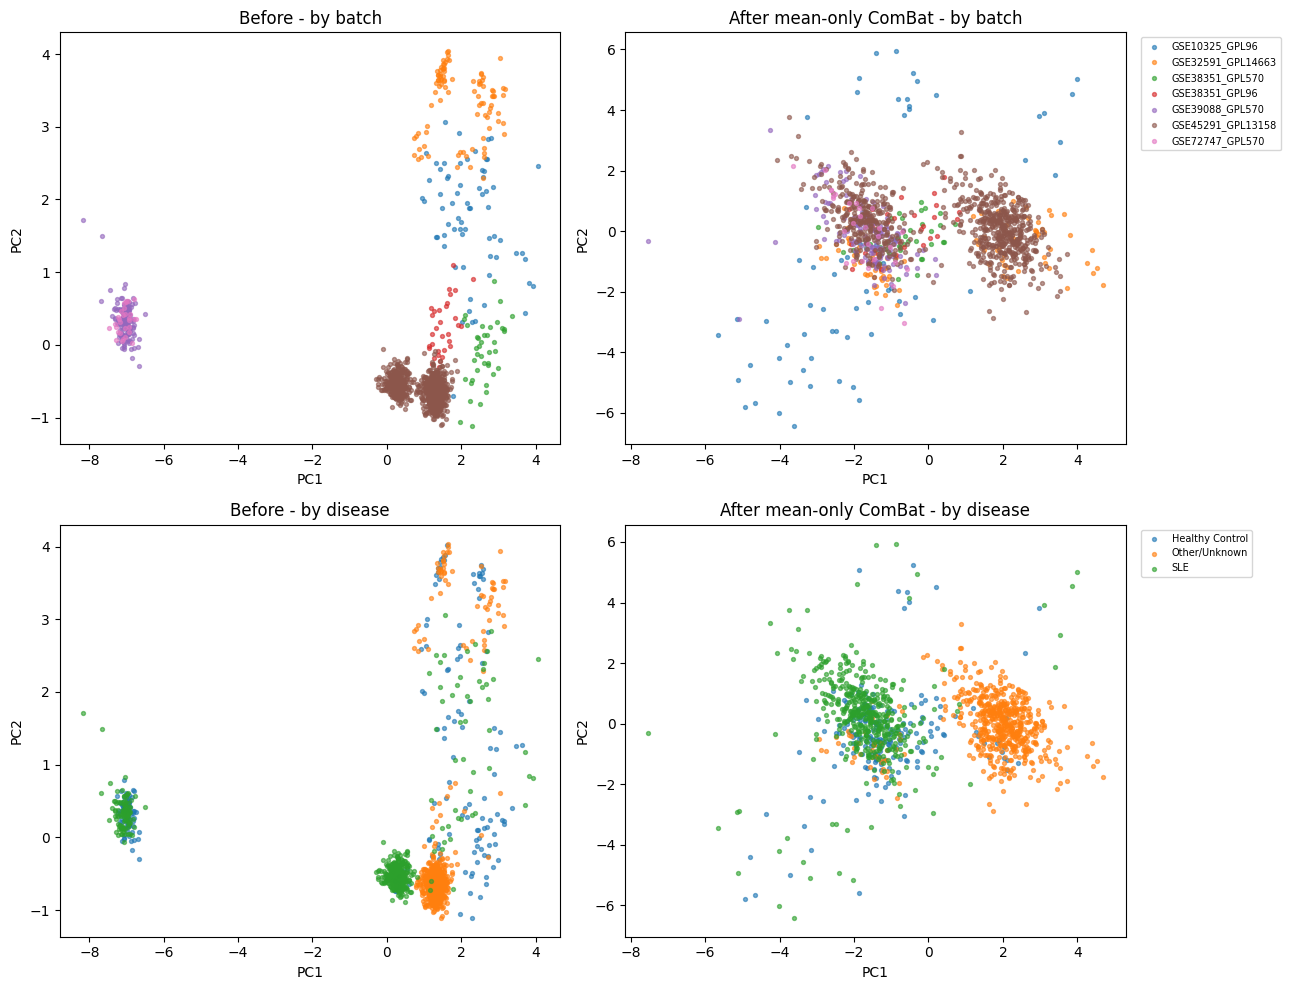

In [ ]:
def pca_scatter(data, ax, color_by, title):
    X = data.T.values
    X = (X - X.mean(0)) / X.std(0)
    pcs = PCA(2).fit_transform(X)
    for lab in sorted(pd.Series(color_by).unique()):
        m = (np.asarray(color_by) == lab)
        ax.scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=.6, label=lab)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
pca_scatter(expr,         axes[0, 0], batch,   "Before - by batch")
pca_scatter(corrected_mo, axes[0, 1], batch,   "After mean-only ComBat - by batch")
pca_scatter(expr,         axes[1, 0], disease, "Before - by disease")
pca_scatter(corrected_mo, axes[1, 1], disease, "After mean-only ComBat - by disease")
axes[0, 1].legend(fontsize=7, bbox_to_anchor=(1.02, 1))
axes[1, 1].legend(fontsize=7, bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig("pca_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Within-dataset SLE vs Healthy effect sizes (distortion check)

In [ ]:
usable = []
for b in df["batch"].unique():
    c = df.loc[df["batch"] == b, "Disease_State"].value_counts()
    if c.get("SLE", 0) >= 3 and c.get("Healthy Control", 0) >= 3:
        usable.append(b)
print("Batches with both SLE and Healthy (>=3 each):", usable)

def effects(data):
    diff = pd.DataFrame(index=data.index, columns=usable, dtype=float)
    cohd = diff.copy()
    for b in usable:
        sle = df.loc[(df.batch == b) & (df.Disease_State == "SLE"), "GSM_ID"]
        hc  = df.loc[(df.batch == b) & (df.Disease_State == "Healthy Control"), "GSM_ID"]
        A, B = data[sle], data[hc]
        n1, n2 = A.shape[1], B.shape[1]
        sp = np.sqrt(((n1 - 1) * A.var(axis=1) + (n2 - 1) * B.var(axis=1)) / (n1 + n2 - 2))
        diff[b] = A.mean(axis=1) - B.mean(axis=1)
        cohd[b] = diff[b] / sp
    return diff, cohd

def summarize(diff, cohd):
    sign = np.sign(cohd)
    majority = np.sign(sign.sum(axis=1))
    concord = (sign.T == majority).T.mean(axis=1)
    return {"sign concordance (mean)":         concord.mean(),
            "SD of Cohen's d across datasets": cohd.std(axis=1).mean(),
            "SD of mean diff across datasets": diff.std(axis=1).mean()}

diff_b, d_b = effects(expr)
diff_m, d_m = effects(corrected_mo)
diff_f, d_f = effects(corrected_full)
summ = pd.DataFrame({"Before": summarize(diff_b, d_b),
                     "Mean-only": summarize(diff_m, d_m),
                     "Full ComBat": summarize(diff_f, d_f)})
print(summ.round(3))
print("\nCohen's d, mean-only:\n", d_m.round(2))
summ.round(4).to_csv("effect_consistency_summary.csv")
d_b.round(3).to_csv("cohend_before.csv")
d_m.round(3).to_csv("cohend_meanonly.csv")
d_f.round(3).to_csv("cohend_full.csv")

Batches with both SLE and Healthy (>=3 each): ['GSE10325_GPL96', 'GSE38351_GPL96', 'GSE39088_GPL570', 'GSE45291_GPL13158', 'GSE72747_GPL570']
                                 Before  Mean-only  Full ComBat
sign concordance (mean)           0.745      0.745        0.727
SD of Cohen's d across datasets   0.576      0.576        1.096
SD of mean diff across datasets   0.293      0.293        0.300

Cohen's d, mean-only:
         GSE10325_GPL96  GSE38351_GPL96  GSE39088_GPL570  GSE45291_GPL13158  \
MTHFR            -0.21            0.48             0.21               0.83   
TYMS              0.57            0.13             0.78               0.53   
MTR              -0.14            0.44            -1.06              -0.36   
MTRR              0.33           -0.11            -0.71               0.59   
CYP1A1           -0.00            0.21             0.20               0.09   
GSTT1             0.00           -0.55            -0.36              -0.20   
GSTP1            -0.17          

## 8. SLE vs Healthy test with batch as a covariate
Following Nygaard et al. 2016: test on the harmonized (log2) data with batch in the
model instead of testing on ComBat output alone. Model: expression ~ batch + SLE.

In [ ]:
sub = df[df["Disease_State"].isin(["SLE", "Healthy Control"])].copy()
sub["SLE"] = (sub["Disease_State"] == "SLE").astype(float)

# batches that contain both groups carry the disease information; keep all, batch absorbs offsets
B = pd.get_dummies(sub["batch"], drop_first=True).astype(float)
rows = []
for g in genes_ok:
    X = sm.add_constant(pd.concat([sub[["SLE"]], B], axis=1))
    fit = sm.OLS(sub[g].astype(float), X).fit()
    rows.append({"gene": g,
                 "log2FC_SLE_vs_Healthy": fit.params["SLE"],
                 "SE": fit.bse["SLE"],
                 "t": fit.tvalues["SLE"],
                 "p": fit.pvalues["SLE"]})
res = pd.DataFrame(rows).set_index("gene")
res["FDR_BH"] = multipletests(res["p"], method="fdr_bh")[1]
print(res.round(4))
res.round(5).to_csv("disease_test_batch_adjusted.csv")

        log2FC_SLE_vs_Healthy      SE       t       p  FDR_BH
gene                                                         
MTHFR                  0.0319  0.0362  0.8811  0.3786  0.4299
TYMS                   0.2664  0.0632  4.2185  0.0000  0.0002
MTR                   -0.3158  0.0578 -5.4653  0.0000  0.0000
MTRR                  -0.0587  0.0428 -1.3699  0.1712  0.2354
CYP1A1                 0.0450  0.0524  0.8587  0.3908  0.4299
GSTT1                 -0.1083  0.0768 -1.4092  0.1593  0.2354
GSTP1                 -0.1760  0.0678 -2.5971  0.0096  0.0265
TLR2                   0.2070  0.1086  1.9062  0.0571  0.1256
TLR4                   0.1491  0.0995  1.4986  0.1345  0.2354
TLR7                   0.0292  0.1125  0.2594  0.7954  0.7954
STAT4                 -0.2476  0.0865 -2.8621  0.0043  0.0159


## 9. Save final datasets

In [ ]:
meta = df[["GSE_ID", "GSM_ID", "GPL", "Disease_State", "Data_Type", "title"]].reset_index(drop=True)

final = pd.concat([meta, corrected_mo.T.reset_index(drop=True)], axis=1)
final.to_csv("database_combat_meanonly.csv", index=False)

# optional: one global z-score across ALL samples (never per dataset)
final_z = final.copy()
final_z[genes_ok] = (final[genes_ok] - final[genes_ok].mean()) / final[genes_ok].std()
final_z.to_csv("database_combat_meanonly_zscore.csv", index=False)

# sensitivity: full ComBat
full_out = pd.concat([meta, corrected_full.T.reset_index(drop=True)], axis=1)
full_out.to_csv("database_combat_full_sensitivity.csv", index=False)

print("Saved:", final.shape, final_z.shape, full_out.shape)

if IN_COLAB:
    for f in ["database_combat_meanonly.csv", "database_combat_meanonly_zscore.csv",
              "metrics_batch_correction.csv", "disease_test_batch_adjusted.csv",
              "pca_before_after.png"]:
        files.download(f)

Saved: (1211, 17) (1211, 17) (1211, 17)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>